In [1]:
import sys, pyspark
print(sys.executable)
print(pyspark.__version__)

/mnt/c/Users/samya.taqi/Desktop/SAMYATAQI/NLP-Computer-vision/PysparkML/.venv/bin/python
4.2.0


#   Import

In [75]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml import Pipeline


from pyspark.ml.evaluation import MulticlassClassificationEvaluator



In [5]:
spark = SparkSession.builder.appName("Mushrooms").master("local[*]").getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/27 10:17:13 WARN Utils: Your hostname, Greta-265-004, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/27 10:17:13 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/27 10:17:14 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [34]:
df = spark.read.csv("dataset/mushrooms.csv", header=True, inferSchema=True)
df.printSchema()
print(df.count(), "lignes,", len(df.columns), "colonnes")

root
 |-- class: string (nullable = true)
 |-- cap-shape: string (nullable = true)
 |-- cap-surface: string (nullable = true)
 |-- cap-color: string (nullable = true)
 |-- bruises: string (nullable = true)
 |-- odor: string (nullable = true)
 |-- gill-attachment: string (nullable = true)
 |-- gill-spacing: string (nullable = true)
 |-- gill-size: string (nullable = true)
 |-- gill-color: string (nullable = true)
 |-- stalk-shape: string (nullable = true)
 |-- stalk-root: string (nullable = true)
 |-- stalk-surface-above-ring: string (nullable = true)
 |-- stalk-surface-below-ring: string (nullable = true)
 |-- stalk-color-above-ring: string (nullable = true)
 |-- stalk-color-below-ring: string (nullable = true)
 |-- veil-type: string (nullable = true)
 |-- veil-color: string (nullable = true)
 |-- ring-number: string (nullable = true)
 |-- ring-type: string (nullable = true)
 |-- spore-print-color: string (nullable = true)
 |-- population: string (nullable = true)
 |-- habitat: string 

## Compréhension des features: 
"""
Forme du chapeau (cap-shape) : cloche=b, conique=c, convexe=x, plat=f, mamelonné=k, déprimé=s
Surface du chapeau (cap-surface) : fibreuse=f, sillonnée=g, écailleuse=y, lisse=s
Couleur du chapeau (cap-color) : brun=n, chamois=b, cannelle=c, gris=g, vert=r, rose=p, violet=u, rouge=e, blanc=w, jaune=y
Meurtrissures (bruises) : oui=t, non=f
Odeur (odor) : amande=a, anis=l, créosote=c, poisson=y, fétide=f, moisi=m, aucune=n, âcre=p, épicée=s
Attache des lamelles (gill-attachment) : adnées=a, décurrentes=d, libres=f, échancrées=n
Espacement des lamelles (gill-spacing) : serrées=c, très serrées=w, espacées=d
Taille des lamelles (gill-size) : larges=b, étroites=n
Couleur des lamelles (gill-color) : noir=k, brun=n, chamois=b, chocolat=h, gris=g, vert=r, orange=o, rose=p, violet=u, rouge=e, blanc=w, jaune=y
Forme du pied (stalk-shape) : s’élargissant=e, s’amincissant=t
Base du pied (stalk-root) : bulbeuse=b, en massue=c, en coupe=u, égale=e, rhizomorphes=z, radicante=r, manquante=?
Surface du pied au-dessus de l’anneau (stalk-surface-above-ring) : fibreuse=f, écailleuse=y, soyeuse=k, lisse=s
Surface du pied sous l’anneau (stalk-surface-below-ring) : fibreuse=f, écailleuse=y, soyeuse=k, lisse=s
Couleur du pied au-dessus de l’anneau (stalk-color-above-ring) : brun=n, chamois=b, cannelle=c, gris=g, orange=o, rose=p, rouge=e, blanc=w, jaune=y
Couleur du pied sous l’anneau (stalk-color-below-ring) : brun=n, chamois=b, cannelle=c, gris=g, orange=o, rose=p, rouge=e, blanc=w, jaune=y
Type de voile (veil-type) : partiel=p, universel=u
Couleur du voile (veil-color) : brun=n, orange=o, blanc=w, jaune=y
Nombre d’anneaux (ring-number) : aucun=n, un=o, deux=t
Type d’anneau (ring-type) : cortiniforme (en toile d’araignée)=c, fugace=e, évasé=f, grand=l, aucun=n, pendant=p, engainant=s, zoné=z
Couleur de la sporée (spore-print-color) : noir=k, brun=n, chamois=b, chocolat=h, vert=r, orange=o, violet=u, blanc=w, jaune=y
Population (population) : abondante=a, en touffes=c, nombreuse=n, dispersée=s, quelques-uns=v, solitaire=y
Habitat (habitat) : herbes=g, feuilles=l, prairies=m, chemins=p, urbain=u, terrains vagues=w, bois=d"""

In [ ]:
df.show(5)
"""e: comestible, p:toxique"""

+-----+---------+-----------+---------+-------+----+---------------+------------+---------+----------+-----------+----------+------------------------+------------------------+----------------------+----------------------+---------+----------+-----------+---------+-----------------+----------+-------+
|class|cap-shape|cap-surface|cap-color|bruises|odor|gill-attachment|gill-spacing|gill-size|gill-color|stalk-shape|stalk-root|stalk-surface-above-ring|stalk-surface-below-ring|stalk-color-above-ring|stalk-color-below-ring|veil-type|veil-color|ring-number|ring-type|spore-print-color|population|habitat|
+-----+---------+-----------+---------+-------+----+---------------+------------+---------+----------+-----------+----------+------------------------+------------------------+----------------------+----------------------+---------+----------+-----------+---------+-----------------+----------+-------+
|    p|        x|          s|        n|      t|   p|              f|           c|        n|   

'e: comestible, p:toxique, x: inconnu, s: dégradé , f: fongique, y: pourri, a: abîmé,\n c: corrompu, n: non comestible, b: brun, e: blanc, g: gris, p: rose, u: pourpre,\n  w: brun clair, o: orange, r: rouge, y: jaune'

**Répartition des classes**

In [37]:
df.groupBy("class").count().show()


+-----+-----+
|class|count|
+-----+-----+
|    e| 4208|
|    p| 3916|
+-----+-----+



In [39]:
df.describe().show()

26/10/27 10:58:05 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-----+---------+-----------+---------+-------+----+---------------+------------+---------+----------+-----------+----------+------------------------+------------------------+----------------------+----------------------+---------+----------+-----------+---------+-----------------+----------+-------+
|summary|class|cap-shape|cap-surface|cap-color|bruises|odor|gill-attachment|gill-spacing|gill-size|gill-color|stalk-shape|stalk-root|stalk-surface-above-ring|stalk-surface-below-ring|stalk-color-above-ring|stalk-color-below-ring|veil-type|veil-color|ring-number|ring-type|spore-print-color|population|habitat|
+-------+-----+---------+-----------+---------+-------+----+---------------+------------+---------+----------+-----------+----------+------------------------+------------------------+----------------------+----------------------+---------+----------+-----------+---------+-----------------+----------+-------+
|  count| 8124|     8124|       8124|     8124|   8124|8124|          

**valeurs manquantes**


In [26]:
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show(vertical=True)

-RECORD 0-----------------------
 class                    | 0   
 cap-shape                | 0   
 cap-surface              | 0   
 cap-color                | 0   
 bruises                  | 0   
 odor                     | 0   
 gill-attachment          | 0   
 gill-spacing             | 0   
 gill-size                | 0   
 gill-color               | 0   
 stalk-shape              | 0   
 stalk-root               | 0   
 stalk-surface-above-ring | 0   
 stalk-surface-below-ring | 0   
 stalk-color-above-ring   | 0   
 stalk-color-below-ring   | 0   
 veil-type                | 0   
 veil-color               | 0   
 ring-number              | 0   
 ring-type                | 0   
 spore-print-color        | 0   
 population               | 0   
 habitat                  | 0   



**Valeurs manquantes encodés**

In [ ]:
df.select([F.sum((F.col(c) == "?").cast("int")).alias(c) for c in df.columns]).show(vertical=True)
"""stalk-root: 2480 valeurs manquantes encodées par "?" (~20% des données)"""

-RECORD 0------------------------
 class                    | 0    
 cap-shape                | 0    
 cap-surface              | 0    
 cap-color                | 0    
 bruises                  | 0    
 odor                     | 0    
 gill-attachment          | 0    
 gill-spacing             | 0    
 gill-size                | 0    
 gill-color               | 0    
 stalk-shape              | 0    
 stalk-root               | 2480 
 stalk-surface-above-ring | 0    
 stalk-surface-below-ring | 0    
 stalk-color-above-ring   | 0    
 stalk-color-below-ring   | 0    
 veil-type                | 0    
 veil-color               | 0    
 ring-number              | 0    
 ring-type                | 0    
 spore-print-color        | 0    
 population               | 0    
 habitat                  | 0    



'stalk-root: 2480 valeurs manquantes encodées par "?" (20% des données)'

**Nombre de modalité par colonne: nbr de valeurs distinctes pour chaque colonne**

In [31]:
df.agg(*(F.countDistinct(c).alias(c) for c in df.columns)).show(vertical=True) 
"""veil-type : une seule valeur, je vais supprimer cette colonne"""

-RECORD 0-----------------------
 class                    | 2   
 cap-shape                | 6   
 cap-surface              | 4   
 cap-color                | 10  
 bruises                  | 2   
 odor                     | 9   
 gill-attachment          | 2   
 gill-spacing             | 2   
 gill-size                | 2   
 gill-color               | 12  
 stalk-shape              | 2   
 stalk-root               | 5   
 stalk-surface-above-ring | 4   
 stalk-surface-below-ring | 4   
 stalk-color-above-ring   | 9   
 stalk-color-below-ring   | 9   
 veil-type                | 1   
 veil-color               | 4   
 ring-number              | 3   
 ring-type                | 5   
 spore-print-color        | 9   
 population               | 6   
 habitat                  | 7   



'veil-type : une seule valeur, je vais supprimer cette colonne'

**Spark SQL sur la colonne de l'odeur : pour regarder la relation de odor et classe**


In [ ]:
df.createOrReplaceTempView("mushrooms")
spark.sql("""
    SELECT odor, class, COUNT(*) AS n
    FROM mushrooms
    GROUP BY odor, class
    ORDER BY odor, class
""").show()

+----+-----+----+
|odor|class|   n|
+----+-----+----+
|   a|    e| 400|
|   c|    p| 192|
|   f|    p|2160|
|   l|    e| 400|
|   m|    p|  36|
|   n|    e|3408|
|   n|    p| 120|
|   p|    p| 256|
|   s|    p| 576|
|   y|    p| 576|
+----+-----+----+



In [ ]:

df.groupBy("spore-print-color").pivot("class").count().fillna(0).orderBy("spore-print-color").show() # 

+-----------------+----+----+
|spore-print-color|   e|   p|
+-----------------+----+----+
|                b|  48|   0|
|                h|  48|1584|
|                k|1648| 224|
|                n|1744| 224|
|                o|  48|   0|
|                r|   0|  72|
|                u|  48|   0|
|                w| 576|1812|
|                y|  48|   0|
+-----------------+----+----+



**Visualisation**

/mnt/c/Users/samya.taqi/Desktop/SAMYATAQI/NLP-Computer-vision/PysparkML/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/mnt/c/Users/samya.taqi/Desktop/SAMYATAQI/NLP-Computer-vision/PysparkML/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


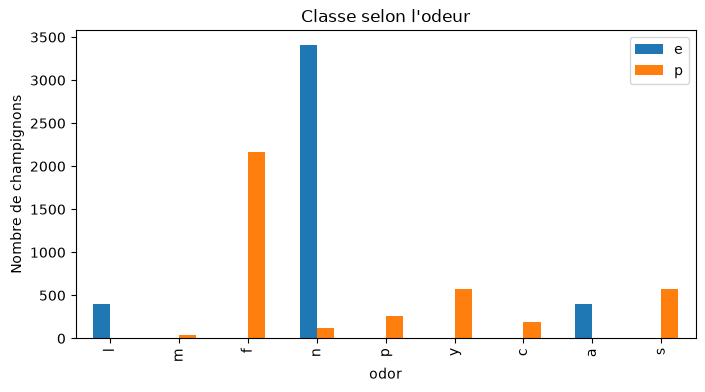

In [51]:
pdf = df.groupBy("odor").pivot("class").count().fillna(0).toPandas().set_index("odor")
pdf.plot(kind="bar", figsize=(8, 4), title="Classe selon l'odeur")
plt.ylabel("Nombre de champignons")
plt.show()

/mnt/c/Users/samya.taqi/Desktop/SAMYATAQI/NLP-Computer-vision/PysparkML/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/mnt/c/Users/samya.taqi/Desktop/SAMYATAQI/NLP-Computer-vision/PysparkML/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


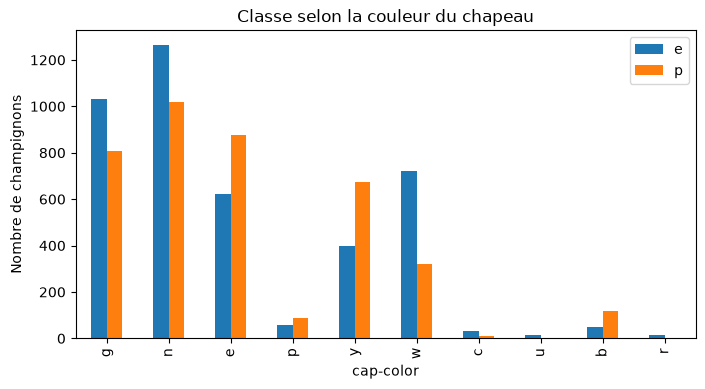

In [73]:
pdf = df.groupBy("cap-color").pivot("class").count().fillna(0).toPandas().set_index("cap-color")
pdf.plot(kind="bar", figsize=(8, 4), title="Classe selon la couleur du chapeau")
plt.ylabel("Nombre de champignons")
plt.show()

/mnt/c/Users/samya.taqi/Desktop/SAMYATAQI/NLP-Computer-vision/PysparkML/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/mnt/c/Users/samya.taqi/Desktop/SAMYATAQI/NLP-Computer-vision/PysparkML/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


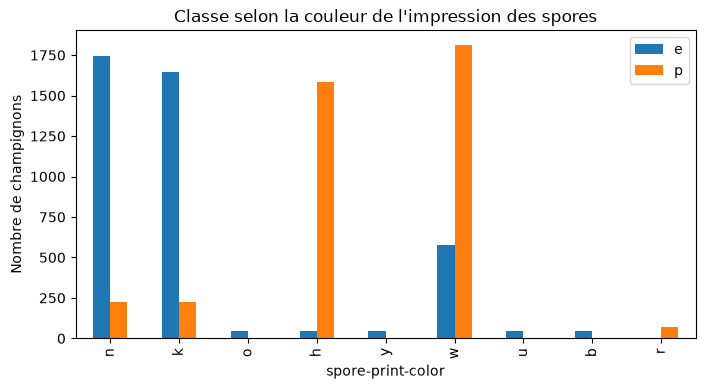

In [74]:
pdf = df.groupBy("spore-print-color").pivot("class").count().fillna(0).toPandas().set_index("spore-print-color")
pdf.plot(kind="bar", figsize=(8, 4), title="Classe selon la couleur de l'impression des spores")
plt.ylabel("Nombre de champignons")
plt.show()

**Nettoyage pour la modèlisation**

In [53]:
df_clean = (
    df.drop("veil-type") # puisque il y a une seule valeur
      .withColumn("stalk-root", F.when(F.col("stalk-root") == "?", "missing").otherwise(F.col("stalk-root"))) # qui contient ~20% de valeurs manquantes, je vais les remplacer par "missing"
)
df_clean.groupBy("stalk-root").count().show()

+----------+-----+
|stalk-root|count|
+----------+-----+
|         e| 1120|
|         c|  556|
|   missing| 2480|
|         b| 3776|
|         r|  192|
+----------+-----+



In [58]:
df_clean.count(), "lignes,", len(df_clean.columns), "colonnes"

(8124, 'lignes,', 22, 'colonnes')

## Préparation des transformations: Utilsation du model RandomForst

In [ ]:
features_cols = [c for c in df_clean.columns if c != "class"]

indexers = [StringIndexer(inputCol=c, outputCol=c + "_index", handleInvalid = "keep") for c in features_cols] # keep évite le plantage si API reçoit une valeur jamais vue
label_indexer = StringIndexer(inputCol="class", outputCol="label") 

assembler = VectorAssembler(inputCols=[c + "_index" for c in features_cols], outputCol="features") # features + target

rf = RandomForestClassifier(labelCol="label", featuresCol="features", numTrees=100)


pipeline = Pipeline(stages=indexers + [label_indexer, assembler, rf])


In [66]:
train , test = df_clean.randomSplit([0.8, 0.2], seed = 0)
print("train:", train.count(), "lignes,", len(train.columns), "colonnes")
print("test:", test.count(), "lignes", len(test.columns), "colonnes")
model = pipeline.fit(train)

train: 6452 lignes, 22 colonnes
test: 1672 lignes 22 colonnes


In [70]:
prediction = model.transform(test)
prediction.select("class", "label", "prediction").show()

+-----+-----+----------+
|class|label|prediction|
+-----+-----+----------+
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
|    e|  0.0|       0.0|
+-----+-----+----------+
only showing top 20 rows


## Métriques 


In [ ]:
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")

for metric in ["accuracy", "f1", "weightedPrecision", "weightedRecall"]:
    score = evaluator.evaluate(prediction, {evaluator.metricName: metric})
    print(f"{metric:18}: {score:.4f}")

accuracy          : 0.9988
f1                : 0.9988
weightedPrecision : 0.9988
weightedRecall    : 0.9988


In [84]:
recall_toxique = evaluator.evaluate(prediction, {evaluator.metricName: "recallByLabel",
                                           evaluator.metricLabel: 1.0})
print(f"Rappel classe toxique : {recall_toxique:.4f}")

Rappel classe toxique : 0.9975


**Matrice de confusion**

In [80]:
confusion_matrix = prediction.groupBy("label", "prediction").count().toPandas()
print(confusion_matrix)

/mnt/c/Users/samya.taqi/Desktop/SAMYATAQI/NLP-Computer-vision/PysparkML/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/mnt/c/Users/samya.taqi/Desktop/SAMYATAQI/NLP-Computer-vision/PysparkML/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


   label  prediction  count
0    1.0         1.0    789
1    1.0         0.0      2
2    0.0         0.0    881


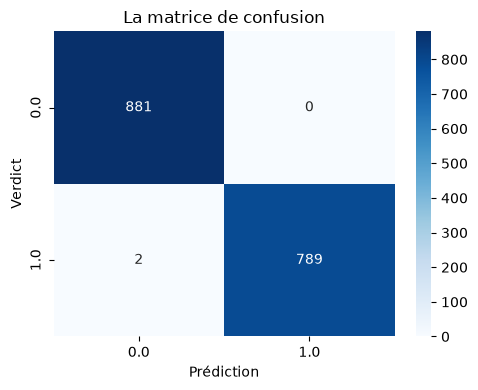

In [92]:
cm = (confusion_matrix.pivot(index="label", columns="prediction", values="count").fillna(0).astype(int)
)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prédiction")
plt.ylabel("Verdict")
plt.title("La matrice de confusion")
plt.tight_layout()
plt.show()

In [93]:


rf_model = model.stages[-1]
importances = pd.Series(rf_model.featureImportances.toArray(), index=features_cols)
print(importances.sort_values(ascending=False).head(10))        

odor                        0.381433
spore-print-color           0.189108
stalk-surface-above-ring    0.071910
gill-size                   0.069297
stalk-surface-below-ring    0.061661
gill-color                  0.044405
population                  0.037724
ring-number                 0.028263
ring-type                   0.019328
stalk-root                  0.018698
dtype: float64
